<a href="https://colab.research.google.com/github/DevalGarg129/SignVision/blob/main/SignVision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
import os
import glob
import random
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from tqdm.auto import tqdm

In [16]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Pytorch : ", torch.__version__)
print("Device : ", device)

if torch.cuda.is_available():
    print("GPU : ", torch.cuda.get_device_name(0))

Pytorch :  2.14.1+cu130
Device :  cuda
GPU :  Tesla T4


In [14]:
path = kagglehub.dataset_download("datamunge/sign-language-mnist")
print("Dataset path:", path)

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))


train_files = glob.glob(
    os.path.join(path, "**", "sign_mnist_train.csv"),
    recursive=True
)

test_files = glob.glob(
    os.path.join(path, "**", "sign_mnist_test.csv"),
    recursive=True
)

assert len(train_files) > 0, "Training CSV not found"
assert len(test_files) > 0, "Testing CSV not found"

train_df = pd.read_csv(train_files[0])
test_df = pd.read_csv(test_files[0])

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

display(train_df.head())

print("Training missing values:", train_df.isnull().sum().sum())
print("Testing missing values:", test_df.isnull().sum().sum())

print("Training duplicate rows:", train_df.duplicated().sum())
print("Testing duplicate rows:", test_df.duplicated().sum())

print("Number of classes:", train_df["label"].nunique())

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Dataset path: /kaggle/input/sign-language-mnist
/kaggle/input/sign-language-mnist/sign_mnist_test.csv
/kaggle/input/sign-language-mnist/amer_sign2.png
/kaggle/input/sign-language-mnist/amer_sign3.png
/kaggle/input/sign-language-mnist/sign_mnist_train.csv
/kaggle/input/sign-language-mnist/american_sign_language.PNG
/kaggle/input/sign-language-mnist/sign_mnist_test/sign_mnist_test.csv
/kaggle/input/sign-language-mnist/sign_mnist_train/sign_mnist_train.csv
Training Shape: (27455, 785)
Testing Shape: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


Training missing values: 0
Testing missing values: 0
Training duplicate rows: 0
Testing duplicate rows: 0
Number of classes: 24


In [17]:
X_train = train_df.drop("label", axis=1).values
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values
y_test = test_df["label"].values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

IMG_SIZE = 28

X_train = X_train.reshape(-1, 1, IMG_SIZE, IMG_SIZE)
X_test = X_test.reshape(-1, 1, IMG_SIZE, IMG_SIZE)

X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

X_train: (27455, 784)
y_train: (27455,)
X_test: (7172, 784)
y_test: (7172,)
Training: (27455, 1, 28, 28)
Testing: (7172, 1, 28, 28)


In [18]:
classes = sorted(np.unique(y_train))

label_mapping = {
    original: encoded
    for encoded, original in enumerate(classes)
}

idx_to_class = {
    encoded: chr(ord('A') + original)
    for original, encoded in label_mapping.items()
}

y_train = np.array([
    label_mapping[label] for label in y_train
])

y_test = np.array([
    label_mapping[label] for label in y_test
])

NUM_CLASSES = len(classes)

print("Number of classes:", NUM_CLASSES)
print("Label mapping:", label_mapping)
print("Class names:", idx_to_class)

Number of classes: 24
Label mapping: {np.int64(0): 0, np.int64(1): 1, np.int64(2): 2, np.int64(3): 3, np.int64(4): 4, np.int64(5): 5, np.int64(6): 6, np.int64(7): 7, np.int64(8): 8, np.int64(10): 9, np.int64(11): 10, np.int64(12): 11, np.int64(13): 12, np.int64(14): 13, np.int64(15): 14, np.int64(16): 15, np.int64(17): 16, np.int64(18): 17, np.int64(19): 18, np.int64(20): 19, np.int64(21): 20, np.int64(22): 21, np.int64(23): 22, np.int64(24): 23}
Class names: {0: 'A', 1: 'B', 2: 'C', 3: 'D', 4: 'E', 5: 'F', 6: 'G', 7: 'H', 8: 'I', 9: 'K', 10: 'L', 11: 'M', 12: 'N', 13: 'O', 14: 'P', 15: 'Q', 16: 'R', 17: 'S', 18: 'T', 19: 'U', 20: 'V', 21: 'W', 22: 'X', 23: 'Y'}


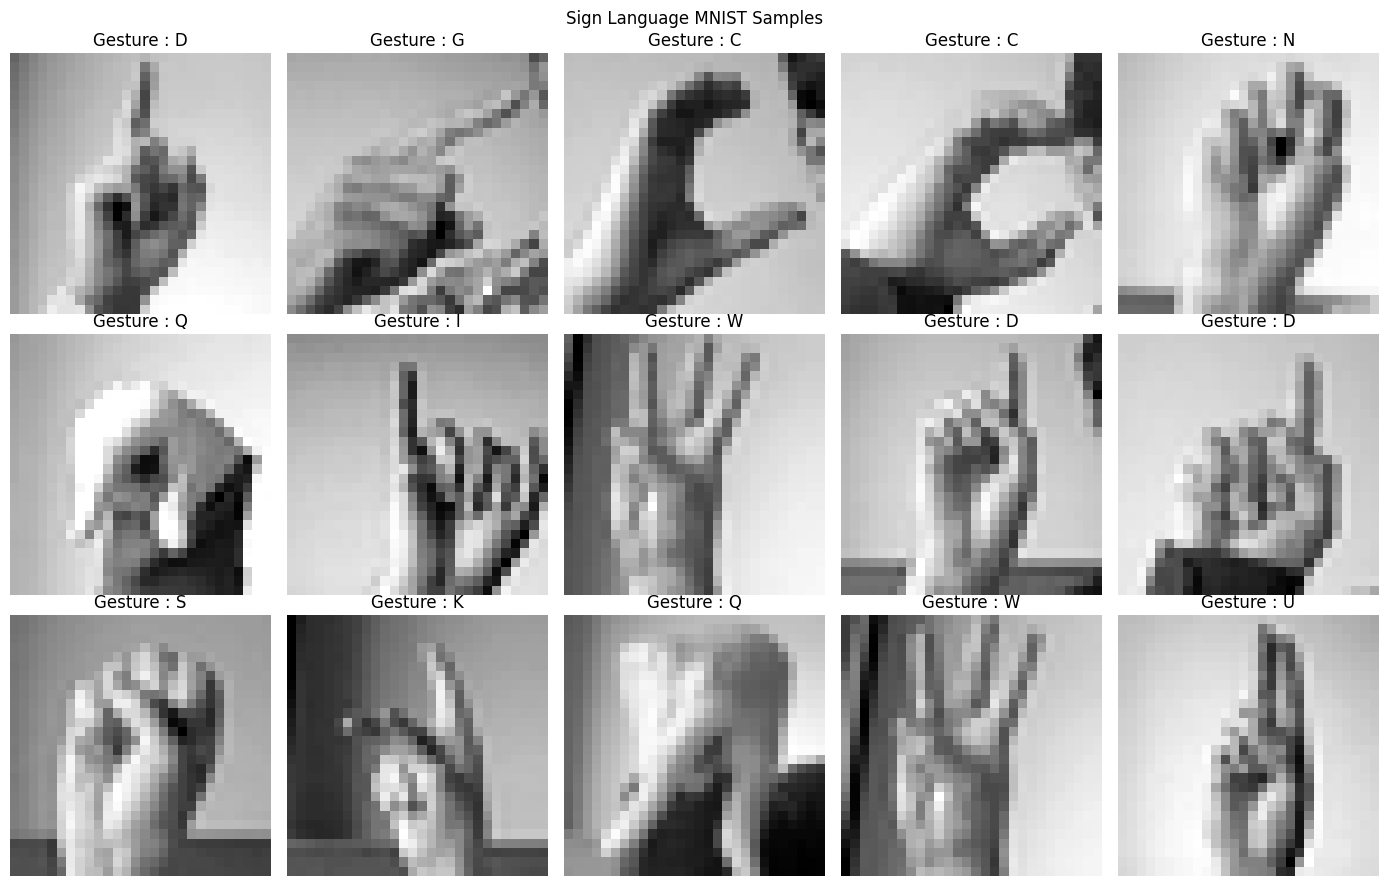

In [19]:
fig, axes = plt.subplots(3, 5, figsize=(14, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i, 0], cmap="gray")
    ax.set_title(f"Gesture : {idx_to_class[y_train[i]]}")
    ax.axis("off")

plt.suptitle("Sign Language MNIST Samples")
plt.tight_layout()
plt.show()

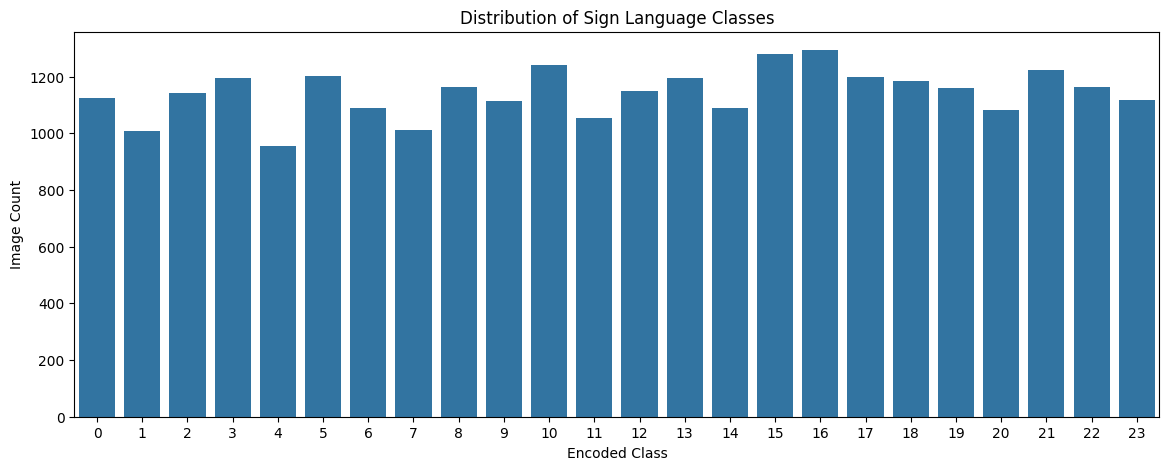

In [20]:
plt.figure(figsize=(14, 5))
sns.countplot(x=y_train)

plt.title("Distribution of Sign Language Classes")
plt.xlabel("Encoded Class")
plt.ylabel("Image Count")
plt.show()

In [21]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)
print("Training : ", X_train.shape)
print("Validation : ", X_val.shape)
print("Testing : ", X_test.shape)

Training :  (23336, 1, 28, 28)
Validation :  (4119, 1, 28, 28)
Testing :  (7172, 1, 28, 28)


In [22]:
class SignLanguageDataset:
    def __init__(self, images, labels):
        self.images = torch.tensor(images, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index]
        label = self.labels[index]

        return image, label

# Dataset Loader
train_dataset = SignLanguageDataset(X_train, y_train)
val_dataset = SignLanguageDataset(X_val, y_val)
test_dataset = SignLanguageDataset(X_test, y_test)

BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size = BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
images, labels = next(iter(train_loader))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Training batches: 365
Validation batches: 65
Testing batches: 113
Image batch: torch.Size([64, 1, 28, 28])
Label batch: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64


In [23]:
class GestureCNN(nn.Module):
    def __init__(self, num_classes=24):
        super(GestureCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        self.avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),  # Fixed here
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avg_pool(x)
        x = self.classifier(x)
        return x

model = GestureCNN(
    num_classes=NUM_CLASSES
).to(device)

print(model)

dummy_input = torch.randn(64, 1, 28, 28).to(device)

output = model(dummy_input)
print("Input shape:", dummy_input.shape)
print("Output shape:", output.shape)

GestureCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
  )
  (avg_pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout

In [24]:
total_params = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total Parameters : ", total_params)
print("Total Trainable Parameters : ", trainable_params)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)
EPOCHS = 20

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(loader, desc="Training")

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Loss calculation
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{100 * correct / total:.2f}%"
        )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    # IMPORTANT: Return must be outside the for loop
    return epoch_loss, epoch_accuracy

def validate_one_epoch(model, loader, criterion):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, dim=1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

Total Parameters :  102936
Total Trainable Parameters :  102936


In [25]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

best_val_accuracy = 0.0

for epoch in range(EPOCHS):
    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion
    )
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_acc:.2f}%")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.2f}%")

    # Best Model Saved
    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        torch.save(
            model.state_dict(),
            "best_gesture_cnn.pth"
        )
        print("Best Model Saved")

print("\n Training Completed!!")
print("Best Validation Accuracy : ", best_val_accuracy)


Epoch [1/20]


Training:   0%|          | 0/365 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fbc13d7a5c0>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7fbc13d7a5c0>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'    
self._shutdown_workers()AssertionError: 
can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/

Training Loss: 1.5404
Training Accuracy: 50.56%
Validation Loss: 0.8549
Validation Accuracy: 70.26%
Best Model Saved

Epoch [2/20]


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7fbc13d7a5c0>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7fbc13d7a5c0>self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Training:   0%|          | 0/365 [00:00<?, ?it/s]

... (39 outputs left out)

Training:   0%|          | 0/365 [00:00<?, ?it/s]

Training Loss: 0.0193
Training Accuracy: 99.45%
Validation Loss: 0.7583
Validation Accuracy: 83.05%

Epoch [20/20]


Training:   0%|          | 0/365 [00:00<?, ?it/s]

Training Loss: 0.0267
Training Accuracy: 99.29%
Validation Loss: 0.0274
Validation Accuracy: 98.91%

 Training Completed!!
Best Validation Accuracy :  100.0


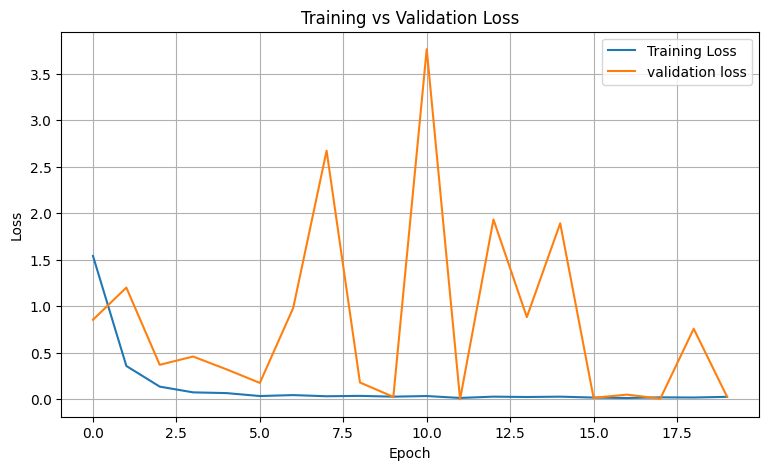

In [26]:
plt.figure(figsize=(9,5))
plt.plot(
    history["train_loss"],
    label="Training Loss"
)
plt.plot(
    history["val_loss"],
    label="validation loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

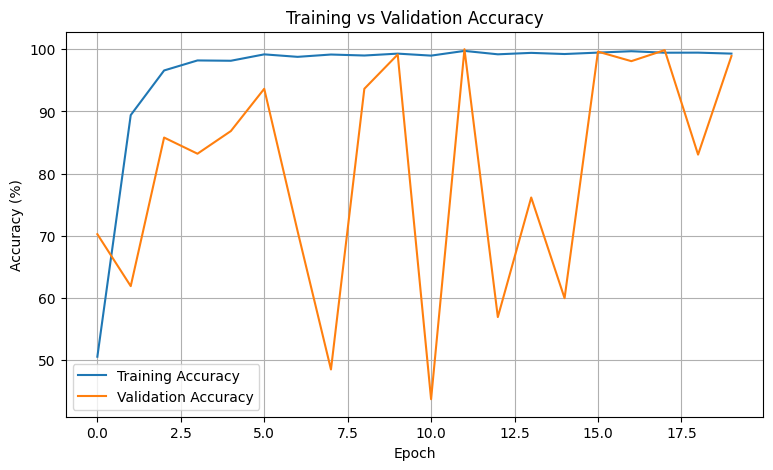

Best model loaded successfully!


In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    history["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid()
plt.show()

model.load_state_dict(
    torch.load(
        "best_gesture_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best model loaded successfully!")

In [28]:
all_predictions = []
all_actuals = []

with torch.no_grad():
    for images, labels in tqdm(test_loader):
        images = images.to(device)
        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )
        all_actuals.extend(
            labels.numpy()
        )

all_predictions = np.array(all_predictions)
all_actuals = np.array(all_actuals)

print("Predictions : ", all_predictions.shape)
print("Actuals : ", all_actuals.shape)

accuracy = accuracy_score(
    all_actuals,
    all_predictions
)

precision = precision_score(
    all_actuals,
    all_predictions,
    average='macro',
    zero_division=0
)

recall = recall_score(
    all_actuals,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_actuals,
    all_predictions,
    average="macro",
    zero_division=0
)

print("MODEL EVALUATED SUCCESSFULLY!!!")

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

  0%|          | 0/113 [00:00<?, ?it/s]

Predictions :  (7172,)
Actuals :  (7172,)
MODEL EVALUATED SUCCESSFULLY!!!
Accuracy  : 96.31%
Precision : 95.97%
Recall    : 96.08%
F1 Score  : 95.90%
